In [113]:
import os 
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import  seaborn as sns

from  sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV


from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score


In [87]:
#Loading the data 
df=pd.read_csv(r"C:\Users\THIS PC\OneDrive\Desktop\House_Price_Prediction\Hyderbad_House_price.csv")
print('Dataset shape:',df.shape)

Dataset shape: (3660, 7)


In [88]:
print("\nColumns")
print(df.columns)


Columns
Index(['Unnamed: 0', 'title', 'location', 'price(L)', 'rate_persqft',
       'area_insqft', 'building_status'],
      dtype='str')


In [89]:
#Removing unnecessary column
df=df.drop(columns=["Unnamed: 0"],errors="ignore")

In [48]:
df.isnull().sum()

title              0
location           0
price(L)           0
rate_persqft       0
area_insqft        0
building_status    0
dtype: int64

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3660 entries, 0 to 3659
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   title            3660 non-null   str    
 1   location         3660 non-null   str    
 2   price(L)         3660 non-null   float64
 3   rate_persqft     3660 non-null   int64  
 4   area_insqft      3660 non-null   int64  
 5   building_status  3660 non-null   str    
dtypes: float64(1), int64(2), str(3)
memory usage: 301.0 KB


In [31]:
df.describe()

,price(L),rate_persqft,area_insqft,bhk
count,3660.000000,3660.000000,3660.000000,3660.000000
mean,109.624350,5165.003005,2023.506284,1.560109
std,197.596948,5316.490320,1829.832163,1.534141
min,1.320000,125.000000,118.000000,0.000000
25%,26.137500,1555.000000,1280.000000,0.000000
50%,61.130000,4703.000000,1620.000000,2.000000
75%,116.000000,6800.000000,2080.000000,3.000000
max,3600.000000,112474.000000,45000.000000,10.000000


<Axes: xlabel='price(L)', ylabel='Count'>

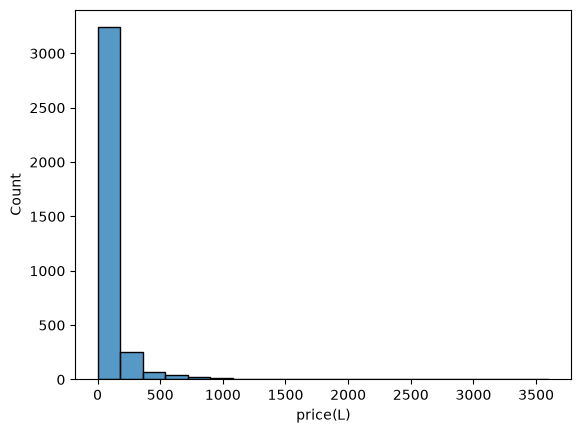

In [53]:
#Plot 1 : Price Distribution
sns.histplot(df["price(L)"],bins=20)

<Axes: xlabel='area_insqft', ylabel='price(L)'>

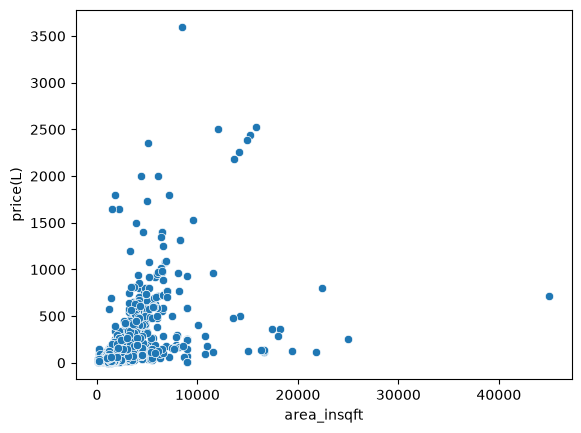

In [ ]:
# Plot -2 : sqft vs price
sns.scatterplot(data=df,x="area_insqft",y="price(L)")

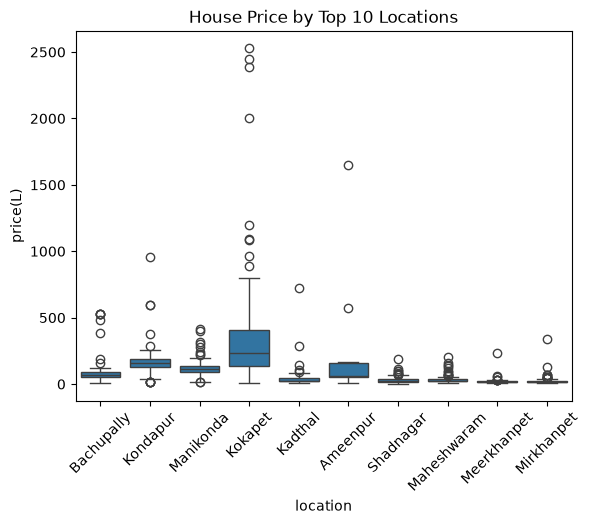

In [60]:
top_locations = df["location"].value_counts().head(10).index

sns.boxplot(
    data=df[df["location"].isin(top_locations)],
    x="location",
    y="price(L)"
)

plt.xticks(rotation=45)
plt.title("House Price by Top 10 Locations")
plt.show()

In [8]:
#Extracting BHK from Title
bhk_vlaues=df["title"].str.extract(r"(\d+)\s*BHK",expand=False)
df["bhk"]=pd.to_numeric(bhk_vlaues,errors="coerce")

In [ ]:
# For RK Studio Apartment assign bhk = 1
df["bhk"]=df["bhk"].fillna(df["title"].str.contains("RK",case=False,na=False).astype(int))
df["bhk"]=df["bhk"].astype(int)

In [13]:
df["title"].unique()

<ArrowStringArray>
[         '3 BHK Apartment',          '2 BHK Apartment',
         'Residential Plot',              '4 BHK Villa',
          '4 BHK Apartment',              '5 BHK Villa',
  '3 BHK Independent House',  '2 BHK Independent House',
  '3 BHK Independent Floor',  '5 BHK Independent House',
 '10 BHK Independent House',  '7 BHK Independent House',
              '3 BHK Villa',  '4 BHK Independent House',
  '8 BHK Independent House',  '6 BHK Independent House',
          '1 BHK Apartment',  '2 BHK Independent Floor',
  '1 BHK Independent House',          '5 BHK Apartment',
  '9 BHK Independent House',    '1 RK Studio Apartment',
  '4 BHK Independent Floor',              '6 BHK Villa',
              '2 BHK Villa']
Length: 25, dtype: str

In [90]:
#Creating Property Type
def get_property_type(title):
    title=title.lower()

    if "residential plot" in title:
        return "Residential Plot"
    elif "independent house" in title:
        return "Independent House"
    elif "independent floor" in title:
        return "Independent Floor"
    elif "villa" in title:
        return "Villa"
    elif "studio" in title:
        return "Studio Apartment"
    elif "apartment" in title:
        return "Apartment"
    else:
        return "Other"

df["property_type"]=df["title"].apply(get_property_type)



In [15]:
df.columns

Index(['title', 'location', 'price(L)', 'rate_persqft', 'area_insqft',
       'building_status', 'bhk', 'property_type'],
      dtype='str')

In [17]:
# Define input Features and Target
"""Note: rate_persqft is NOT used because it directly releated to the target column
 this feature lead to  data lekage to the target column."""
features=['location',  'area_insqft',
       'building_status', 'bhk', 'property_type']
target=["price(L)"]

X=df[features]
y=df[target]


In [19]:
#Train Test Split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
print("\nTraining data:",X_train.shape)
print("\nTesting data:",X_test.shape)



Training data: (2928, 5)

Testing data: (732, 5)


In [ ]:
#Define Numerical Features and Categorical Features
numerical_features=["area_insqft","bhk"]
categorical_features=["location","building_status","property_type"]

#preprocessing
numerical_pipeline=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())])
categorical_pipeline=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehotencoding",OneHotEncoder(handle_unknown="ignore"))])
preprocessor=ColumnTransformer(transformers=[("numerical",numerical_pipeline,numerical_features),
                                             ("categorical",categorical_pipeline,categorical_features)])

#Defining  Models
models={
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(max_iter=20000,random_state=42),
    "Ridge":Ridge(),
    "Random Forest": RandomForestRegressor(random_state=42)
}

#define Parameter Grids
param_grids={
    "Linear Regression":{},
    "Lasso":{
        "model_alpha":[
            0.001,0.01,1,0.1,1,10
        ]
        },
    "Ridge":{
        "model_alpha":[
            0.01,0.1,1,10,100
        ]
    },
    "Random Forest":{
        "model_n_estimators":[100,200,300],
        "model_max_depth":[None,10,20],
        "model_min_samples_split":[2,5]
    }
}

#GridSearchCV
results=[]
best_models={}

for name,model in models.items():
    print("Training:",name)

    pipeline=Pipeline(steps=[("preprocessor",preprocessor),
                         ("model",model)])

    grid_search=GridSearchCV(
    estimator=pipeline,
    param_grid=param_grids[name],
    cv=5,
    scoring="neg_root_mean_squared_error"
    
    )

    grid_search.fit(X_train,y_train)

    print("Best Parameters:",grid_search.best_params_)

    predictions=grid_search.predict(X_test)





In [ ]:
#Define Numerical Features and Categorical Features
numerical_features=["area_insqft","bhk"]
categorical_features=["location","building_status","property_type"]

In [94]:
#Preprocessing
numerical_pipeline=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())])
categorical_pipeline=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehotencoding",OneHotEncoder(handle_unknown="ignore"))])
preprocessor=ColumnTransformer(transformers=[("numerical",numerical_pipeline,numerical_features),
                                             ("categorical",categorical_pipeline,categorical_features)])

In [99]:
print(type(preprocessor))
print(preprocessor)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['area_insqft', 'bhk']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoding',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['location', 'building_status',
                                  'property_type'])])


In [95]:
#Defining  Models
models={
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(max_iter=20000,random_state=42),
    "Ridge":Ridge(),
    "Random Forest": RandomForestRegressor(random_state=42)
}


In [101]:
#define Parameter Grids
param_grids={
    "Linear Regression":{},
    "Lasso":{
        "model__alpha":[
            0.001,0.01,1,0.1,1,10
        ]
        },
    "Ridge":{
        "model__alpha":[
            0.01,0.1,1,10,100
        ]
    },
    "Random Forest":{
        "model__n_estimators":[100,200,300],
        "model__max_depth":[None,10,20],
        "model__min_samples_split":[2,5]
    }
}

In [104]:
#GridSearchCV
results=[]
best_models={}

for name,model in models.items():
    print("Training:",name)

    pipeline=Pipeline(steps=[("preprocessor",preprocessor),
                         ("model",model)])

    grid_search=GridSearchCV(
    estimator=pipeline,
    param_grid=param_grids[name],
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=2
    
    )

    grid_search.fit(X_train,y_train)

    print("Best Parameters:",grid_search.best_params_)

    predictions=grid_search.predict(X_test)


Training: Linear Regression
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best Parameters: {}
Training: Lasso
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'model__alpha': 0.1}
Training: Ridge
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Parameters: {'model__alpha': 1}
Training: Random Forest
Fitting 5 folds for each of 18 candidates, totalling 90 fits


C:\Users\THIS PC\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best Parameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 300}


In [ ]:
# Evaluation Metrics
mae=mean_absolute_error(y_test,predictions)
rmse=np.sqrt(mean_absolute_error(y_test,predictions))
r2=r2_score(y_test,predictions)

results.append({
    "Model":name,
    "MAE":mae,
    "RMSE":rmse,
    "R2":r2
})
best_models[name]=grid_search.best_estimator_

In [108]:
#Model Comparision
results_df=pd.DataFrame(results)
results_df=results_df.sort_values(by="R2",ascending=False)
print("\n----Model Comparision----")
print(results_df.to_string(index=False))


----Model Comparision----
        Model       MAE     RMSE       R2
Random Forest 29.864234 5.464818 0.666345


In [109]:
#Selecting the best model
best_model_name=results_df.iloc[0]["Model"]
best_model=best_models[best_model_name]
print("\nBest Model:",best_model)


Best Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area_insqft', 'bhk']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoding',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                        

In [116]:
#Save the model
joblib.dump(best_model,"models/best_model.pkl")
with open("models/best_model.csv","w") as file:
    file.write(best_model_name)



In [114]:
#Save the results
results_df.to_csv(
    "models/model_results.csv",
    index=False
)


print(
    "\nModel saved successfully!"
)


Model saved successfully!
